In [1]:
# Install Ultralytics (YOLOv8) & Verify GPUTensorFlow and OpenCV are pre-installed in Colab;
# we only need to install ultralytics for YOLOv8.

!pip install ultralytics -q

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16, ResNet50
from ultralytics import YOLO

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
#Load CIFAR-10 Dataset & Define Data AugmentationWe use a clean, balanced subset of CIFAR-10 (3,000 training / 600 test images across 10 classes)
#so all 4 models train in ~2 minutes on your T4 GPU,
#plus a Keras Data Augmentation layer to improve generalization.

(x_train_full, y_train_full), (x_test_full, y_test_full) = tf.keras.datasets.cifar10.load_data()

# Use a fast, clean subset for training & evaluation
x_train = x_train_full[:3000].astype("float32") / 255.0
y_train = y_train_full[:3000].flatten()
x_test = x_test_full[:600].astype("float32") / 255.0
y_test = y_test_full[:600].flatten()

class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

# Data Augmentation pipeline
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

print(f"Train shape: {x_train.shape} | Test shape: {x_test.shape}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1339s 8us/step
Train shape: (3000, 32, 32, 3) | Test shape: (600, 32, 32, 3)


In [3]:
#Train & Evaluate Baseline Models — ANN vs. CNN
#This builds a simple dense ANN and compares it against a spatial CNN with data augmentation.

# 1. Baseline ANN (Flattens image -> loses spatial structure)
ann_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])
ann_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
ann_model.fit(x_train, y_train, epochs=8, batch_size=64, validation_split=0.1, verbose=0)
_, ann_acc = ann_model.evaluate(x_test, y_test, verbose=0)
print(f"ANN Test Accuracy: {ann_acc:.2%}")

# 2. Custom CNN (Preserves spatial features + Data Augmentation)
cnn_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    data_augmentation,
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])
cnn_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn_model.fit(x_train, y_train, epochs=10, batch_size=64, validation_split=0.1, verbose=0)
_, cnn_acc = cnn_model.evaluate(x_test, y_test, verbose=0)
print(f"CNN Test Accuracy: {cnn_acc:.2%}")

ANN Test Accuracy: 27.33%
CNN Test Accuracy: 46.00%


In [4]:
#Transfer Learning with VGG16 & ResNet50
#We load ImageNet-pretrained VGG16 and ResNet50 backbones,
#freeze their feature-extraction layers, resize inputs to 64x64, and train custom classification heads.

def build_transfer_model(base_model_cls, name):
    inputs = layers.Input(shape=(32, 32, 3))
    x = data_augmentation(inputs)
    x = layers.Resizing(64, 64)(x)

    base = base_model_cls(weights="imagenet", include_top=False, input_shape=(64, 64, 3))
    base.trainable = False  # Freeze pretrained ImageNet weights

    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = models.Model(inputs, outputs, name=name)
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

# Train VGG16
vgg_model = build_transfer_model(VGG16, "VGG16_Transfer")
vgg_model.fit(x_train, y_train, epochs=6, batch_size=64, validation_split=0.1, verbose=0)
_, vgg_acc = vgg_model.evaluate(x_test, y_test, verbose=0)
print(f"VGG16 Transfer Learning Test Accuracy: {vgg_acc:.2%}")

# Train ResNet50
resnet_model = build_transfer_model(ResNet50, "ResNet50_Transfer")
resnet_model.fit(x_train, y_train, epochs=6, batch_size=64, validation_split=0.1, verbose=0)
_, resnet_acc = resnet_model.evaluate(x_test, y_test, verbose=0)
print(f"ResNet50 Transfer Learning Test Accuracy: {resnet_acc:.2%}")

# Summary Comparison Table
results_df = pd.DataFrame([
    {"Model": "Custom ANN", "Test Accuracy": f"{ann_acc:.2%}"},
    {"Model": "Custom CNN + Augmentation", "Test Accuracy": f"{cnn_acc:.2%}"},
    {"Model": "VGG16 (Transfer Learning)", "Test Accuracy": f"{vgg_acc:.2%}"},
    {"Model": "ResNet50 (Transfer Learning)", "Test Accuracy": f"{resnet_acc:.2%}"}
])
display(results_df)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
VGG16 Transfer Learning Test Accuracy: 47.33%
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 Transfer Learning Test Accuracy: 19.83%


,Model,Test Accuracy
0,Custom ANN,27.33%
1,Custom CNN + Augmentation,46.00%
2,VGG16 (Transfer Learning),47.33%
3,ResNet50 (Transfer Learning),19.83%



image 1/1 /content/sample_street.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 9.1ms
Speed: 60.3ms preprocess, 9.1ms inference, 27.6ms postprocess per image at shape (1, 3, 640, 480)


,Object,Confidence,"Bounding Box (x1, y1, x2, y2)"
0,bus,87.34%,"(22.9, 231.3, 805.0, 756.8)"
1,person,86.57%,"(48.6, 398.6, 245.3, 902.7)"
2,person,85.28%,"(669.5, 392.2, 809.7, 877.0)"
3,person,82.52%,"(221.5, 405.8, 345.0, 857.5)"
4,person,26.11%,"(0.0, 550.5, 63.0, 873.4)"
5,stop sign,25.51%,"(0.1, 254.5, 32.6, 324.9)"


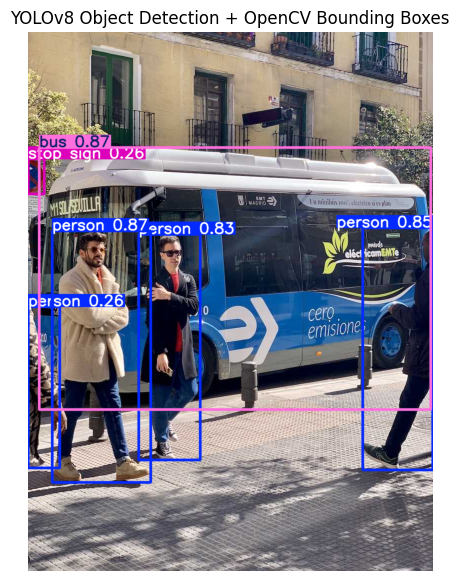

In [5]:
#Real-Time Object Detection with YOLOv8 + OpenCV
#This runs pretrained yolov8n.pt on a sample street image,
#extracts bounding boxes, class labels, and confidence scores, and renders the annotated image using OpenCV and Matplotlib.

import urllib.request

# Download a standard sample image for object detection
img_url = "https://ultralytics.com/images/bus.jpg"
img_path = "sample_street.jpg"
urllib.request.urlretrieve(img_url, img_path)

# Load pretrained YOLOv8 nano model (fast & free)
yolo_model = YOLO("yolov8n.pt")

# Run inference
results = yolo_model(img_path)

# Print detected objects and bounding box coordinates
detections = []
for box in results[0].boxes:
    cls_id = int(box.cls[0])
    conf = float(box.conf[0])
    x1, y1, x2, y2 = [round(float(v), 1) for v in box.xyxy[0]]
    detections.append({
        "Object": yolo_model.names[cls_id],
        "Confidence": f"{conf:.2%}",
        "Bounding Box (x1, y1, x2, y2)": (x1, y1, x2, y2)
    })

display(pd.DataFrame(detections))

# Render annotated image with OpenCV (BGR -> RGB for Matplotlib)
annotated_bgr = results[0].plot()
annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(annotated_rgb)
plt.axis("off")
plt.title("YOLOv8 Object Detection + OpenCV Bounding Boxes")
plt.show()